In [47]:
from wget import download
from os import path
import pandas as pd

if not path.exists("Life-Expectancy-Data-Updated.csv"):
    download("https://ignaciorlando.github.io/datasets/data-science/Life-Expectancy-Data-Updated.csv")
else:
    print("El archivo ya existe")


leer_datos_life = pd.read_csv("Life-Expectancy-Data-Updated.csv")
leer_datos_life.info()

El archivo ya existe
<class 'pandas.DataFrame'>
RangeIndex: 2864 entries, 0 to 2863
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Country                      2864 non-null   str    
 1   Region                       2864 non-null   str    
 2   Year                         2864 non-null   int64  
 3   Infant_deaths                2864 non-null   float64
 4   Under_five_deaths            2864 non-null   float64
 5   Adult_mortality              2864 non-null   float64
 6   Alcohol_consumption          2864 non-null   float64
 7   Hepatitis_B                  2864 non-null   int64  
 8   Measles                      2864 non-null   int64  
 9   BMI                          2864 non-null   float64
 10  Polio                        2864 non-null   int64  
 11  Diphtheria                   2864 non-null   int64  
 12  Incidents_HIV                2864 non-null   float64
 13  GDP_per_

In [48]:
leer_datos_life.head()

,Country,Region,Year,Infant_deaths,Under_five_deaths,Adult_mortality,Alcohol_consumption,Hepatitis_B,Measles,BMI,...,Diphtheria,Incidents_HIV,GDP_per_capita,Population_mln,Thinness_ten_nineteen_years,Thinness_five_nine_years,Schooling,Economy_status_Developed,Economy_status_Developing,Life_expectancy
0,Turkiye,Middle East,2015,11.1,13.0,105.8240,1.32,97,65,27.8,...,97,0.08,11006,78.53,4.9,4.8,7.8,0,1,76.5
1,Spain,European Union,2015,2.7,3.3,57.9025,10.35,97,94,26.0,...,97,0.09,25742,46.44,0.6,0.5,9.7,1,0,82.8
2,India,Asia,2007,51.5,67.9,201.0765,1.57,60,35,21.2,...,64,0.13,1076,1183.21,27.1,28.0,5.0,0,1,65.4
3,Guyana,South America,2006,32.8,40.5,222.1965,5.68,93,74,25.3,...,93,0.79,4146,0.75,5.7,5.5,7.9,0,1,67.0
4,Israel,Middle East,2012,3.4,4.3,57.9510,2.89,97,89,27.0,...,94,0.08,33995,7.91,1.2,1.1,12.8,1,0,81.7


In [49]:
leer_datos_life.isna().sum()

Country                        0
Region                         0
Year                           0
Infant_deaths                  0
Under_five_deaths              0
Adult_mortality                0
Alcohol_consumption            0
Hepatitis_B                    0
Measles                        0
BMI                            0
Polio                          0
Diphtheria                     0
Incidents_HIV                  0
GDP_per_capita                 0
Population_mln                 0
Thinness_ten_nineteen_years    0
Thinness_five_nine_years       0
Schooling                      0
Economy_status_Developed       0
Economy_status_Developing      0
Life_expectancy                0
dtype: int64

# Ejercicio 1

In [50]:
import numpy as np
from sklearn.preprocessing import StandardScaler

life_numeric_cols = leer_datos_life.select_dtypes(include=np.number).columns
scaler_life = StandardScaler()
leer_datos_life[life_numeric_cols] = scaler_life.fit_transform(leer_datos_life[life_numeric_cols])
leer_datos_life.head()

,Country,Region,Year,Infant_deaths,Under_five_deaths,Adult_mortality,Alcohol_consumption,Hepatitis_B,Measles,BMI,...,Diphtheria,Incidents_HIV,GDP_per_capita,Population_mln,Thinness_ten_nineteen_years,Thinness_five_nine_years,Schooling,Economy_status_Developed,Economy_status_Developing,Life_expectancy
0,Turkiye,Middle East,1.626978,-0.699654,-0.671831,-0.752264,-0.879342,0.794574,-0.661700,1.261475,...,0.690747,-0.341998,-0.031593,0.306709,0.007695,-0.022064,0.052941,-0.510454,0.510454,0.812841
1,Spain,European Union,1.626978,-1.004739,-0.889504,-1.169371,1.388788,0.794574,0.892723,0.440877,...,0.690747,-0.337798,0.838721,0.071552,-0.961328,-0.972460,0.652121,1.959040,-1.959040,1.482771
2,India,Asia,-0.108465,0.767660,0.560155,0.076810,-0.816547,-1.518979,-2.269725,-1.747384,...,-1.433965,-0.320998,-0.618062,8.401854,5.010559,5.105658,-0.830060,-0.510454,0.510454,-0.367513
3,Guyana,South America,-0.325396,0.088482,-0.054716,0.260638,0.215791,0.544460,-0.179293,0.121756,...,0.433206,-0.043800,-0.436747,-0.263267,0.187979,0.132652,0.084477,-0.510454,0.510454,-0.197372
4,Israel,Middle East,0.976187,-0.979315,-0.867064,-1.168949,-0.484993,0.794574,0.624719,0.896765,...,0.497592,-0.341998,1.326146,-0.210798,-0.826115,-0.839847,1.629730,1.959040,-1.959040,1.365799


In [51]:
# K-means
from sklearn.cluster import KMeans

datos_paises = (leer_datos_life.sort_values('Year').groupby('Country', as_index=False).tail(1).reset_index(drop=True))

countries_region = datos_paises[['Country', 'Region']].copy()
features_life = leer_datos_life.drop(columns=['Country', 'Region', "Year"])
kmeans_life = KMeans(n_clusters=4, verbose=0, random_state=10).fit(features_life)
clusters_life_kmeans = kmeans_life.labels_
print(clusters_life_kmeans)

[3 1 0 ... 0 1 1]


In [66]:
# Creamos un DataFrame con los países, regiones y clusters asignados
cluster_df = countries_region.copy()
cluster_df['Cluster'] = clusters_life_kmeans

# Imprimimos los países de cada cluster
for cluster_num in range(4):
    print(f"\nCluster {cluster_num}:")
    print(cluster_df[cluster_df['Cluster'] == cluster_num]['Country'].tolist())

ValueError: Length of values (2864) does not match length of index (179)

El algoritmo asigna cada país a un grupo según la similitud de sus características. Luego podemos estudiar los promedios de cada grupo para encontrar patrones.
- Hipótesis 1: los países con mayor PBI per cápita tienden a presentar mayor esperanza de vida.
- Hipótesis 2: los países con mayor escolaridad presentan, en promedio, menor mortalidad infantil y adulta.
- Hipótesis 3: los países con menor esperanza de vida presentan mayores tasas de mortalidad infantil y de menores de cinco años.
- Hipótesis 4: los países desarrollados tienden a agruparse con valores más altos de esperanza de vida y mejores indicadores de salud.

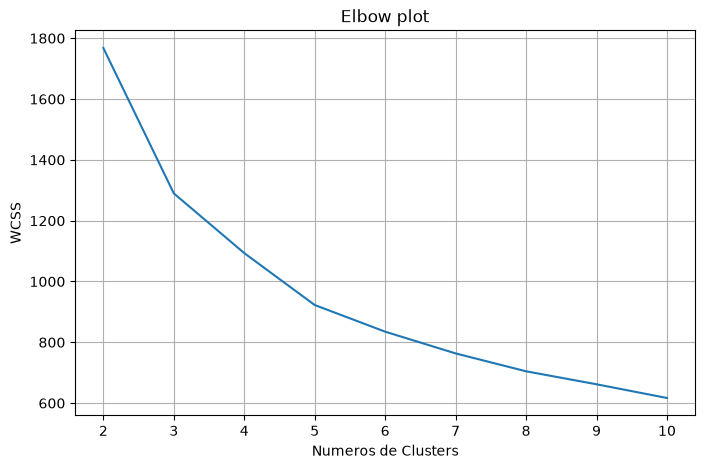

In [ ]:
import matplotlib.pyplot as plt

wcss = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=10, n_init=20)
    kmeans.fit(features_life)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), wcss)
plt.xlabel('Numeros de Clusters')
plt.ylabel('WCSS')
plt.title('Elbow plot')
plt.grid(True)
plt.show()

Como primera comparación, elegiría: 
- K = 3: ofrece una división general entre países con indicadores de salud y desarrollo relativamente mejores y países con indicadores menos favorables.
- K = 5: permite distinguir tres perfiles generales: países con indicadores favorables, países con valores intermedios y países con mayores dificultades sanitarias y económicas.
- K = 7: subdivide alguno de esos perfiles y permite observar diferencias más específicas entre países con indicadores desfavorables.

Silhouette score: mide qué tan cerca está cada país de los integrantes de su propio cluster en comparación con los otros clusters. Va de −1 a 1; cuanto más alto, mejor separación y cohesión.

Davies-Bouldin score: evalúa la similitud entre cada cluster y el más parecido a él. Cuanto más bajo, mejor.

In [ ]:
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score)

resultados_metricas = []

for k in [2, 5, 7]:
    modelo = KMeans(n_clusters=k, random_state=10, n_init=20)

    etiquetas = modelo.fit_predict(features_life)

    resultados_metricas.append({
        'K': k,
        'Inercia': modelo.inertia_,
        'Silhouette': silhouette_score(features_life, etiquetas),
        'Davies-Bouldin': davies_bouldin_score(features_life, etiquetas),
        'Calinski-Harabasz': calinski_harabasz_score(features_life, etiquetas)
    })

tabla_metricas = pd.DataFrame(resultados_metricas)
print(tabla_metricas.round(3))

   K   Inercia  Silhouette  Davies-Bouldin  Calinski-Harabasz
0  2  1767.876       0.338           1.256             89.027
1  5   922.623       0.367           1.087             81.777
2  7   763.405       0.325           1.145             71.110


K = 2 obtiene Calinski-Harabasz, por lo que muestra la mejor separación global según esas dos métricas.

K = 5 obtiene el mejor Davies-Bouldin, lo que sugiere una buena relación entre la dispersión de los grupos y su separación.

K = 7 no mejora las métricas de separación frente a los modelos anteriores, aunque su inercia sea menor.

AttributeError: 'StringArray' object has no attribute 'remove'

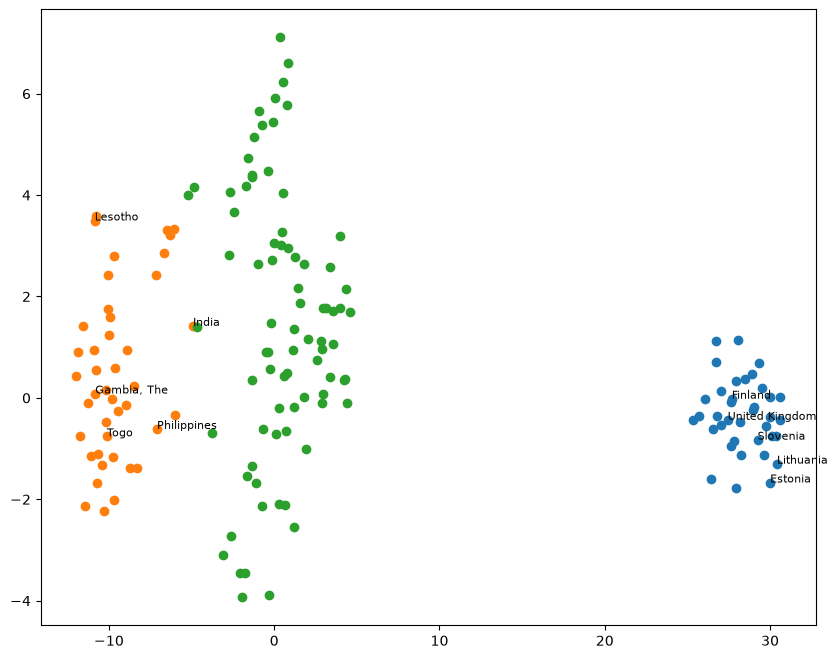

In [ ]:
from sklearn.manifold import TSNE

tsne_life = TSNE(n_components=2, random_state=42)
tsne_life_results = tsne_life.fit_transform(features_life)
tsne_life_datos = pd.DataFrame({'x': tsne_life_results[:, 0], 'y': tsne_life_results[:, 1], 'Cluster' : clusters_life_kmeans, 'Country': countries_region['Country'].to_numpy()})

plt.figure(figsize=(10,8))
for cluster_num in range(4):
    plt.scatter(tsne_life_datos[tsne_life_datos['Cluster'] == cluster_num]['x'], tsne_life_datos[tsne_life_datos['Cluster'] == cluster_num]['y'], label=f"Cluster {cluster_num}")

    countries_to_label = tsne_life_datos[tsne_life_datos['Cluster'] == cluster_num]['Country'].unique()
    if 'Argentina' in countries_to_label:
        countries_to_label.remove('Argentina')
        countries_to_label = ['Argentina'] + countries_to_label[:4]
    else:
        countries_to_label = countries_to_label[:5]

    for country in countries_to_label:
        row = tsne_life_datos[tsne_life_datos['Country'] == country]
        if not row.empty:
            plt.text(row['x'].values[0], row['y'].values[0], country, fontsize=8)

plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.legend()
plt.title('Resultados del clustering con K-means (t-SNE)')
plt.show()

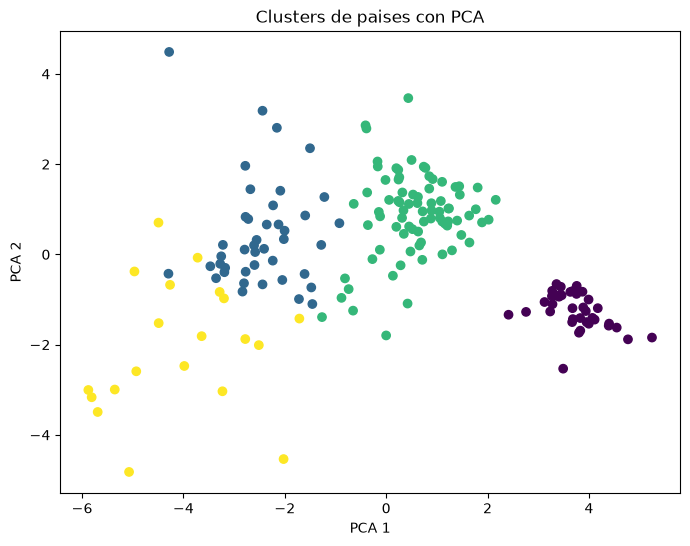

In [ ]:
from sklearn.decomposition import PCA

pca_life = PCA(n_components=2)
datos_pca_life = pca_life.fit_transform(features_life)

plt.figure(figsize=(8, 6))
plt.scatter(datos_pca_life[:, 0], datos_pca_life[:, 1], c=clusters_life_kmeans, cmap='viridis')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('Clusters de paises con PCA')
plt.show()

/home/franco/Escritorio/Facultad/FundamentosCsDatos/TP7/tp7/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


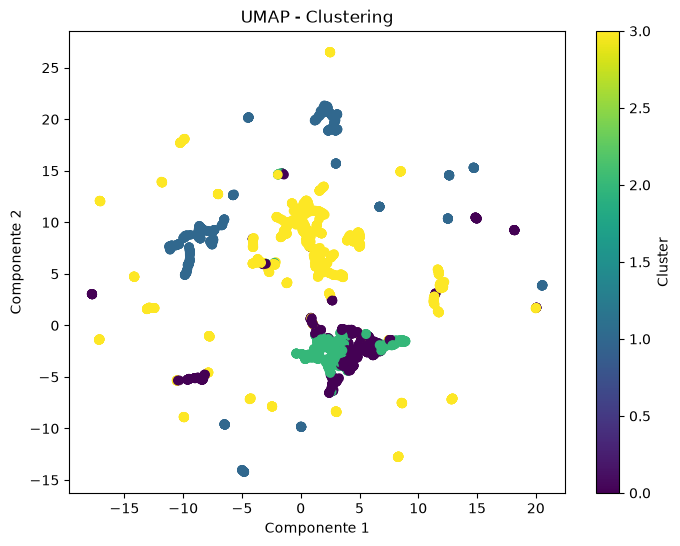

In [62]:
import umap.umap_ as umap
reductor_umap_life = umap.UMAP(n_components=2, random_state=10)
datos_umap_life = reductor_umap_life.fit_transform(features_life)

plt.figure(figsize=(8,6))
plt.scatter(datos_umap_life[:,0], datos_umap_life[:,1], c=clusters_life_kmeans, cmap='viridis')
plt.title('UMAP - Clustering')
plt.xlabel('Componente 1')
plt.ylabel('Componente 2')
plt.colorbar(label='Cluster')
plt.show()

PCA conserva variabilidad global; t-SNE prioriza vecindades locales y UMAP también intenta conservar estructura local y global. Las distancias entre puntos y el tamaño aparente de las regiones no tienen exactamente el mismo significado en las tres técnicas.

Región geográfica y cluster
H: La región geográfica está asociada con el cluster.

Primero, generamos los clusters sin incluir Life_expectancy. Así podremos utilizar esa variable como una medida externa para comparar los grupos.

- H_0: la región y el cluster son independientes.
- H_1: existe una asociación entre la región y el cluster. <br>
Con un nivel de significación de alpha = 0.05

Si el test resulta significativo, podremos investigar qué regiones aparecen con mayor frecuencia en cada grupo. Eso no significa que la región cause las características sanitarias o económicas observadas.

In [57]:
from scipy.stats import chi2_contingency

# Excluimos la variable que queremos estudiar después
features_sin_le = datos_paises.drop(columns=['Country', 'Region', 'Year', 'Life_expectancy'])

# Estandarizamos
X_sin_le = StandardScaler().fit_transform(features_sin_le)

# Agrupamos los países
modelo_sin_le = KMeans(n_clusters=2, random_state=10, n_init=20
)

clusters_sin_le = modelo_sin_le.fit_predict(X_sin_le)

# Agregamos el cluster a los datos
datos_test = datos_paises.copy()
datos_test['Cluster'] = clusters_sin_le
tabla_life = pd.crosstab(datos_test['Region'], datos_test['Cluster'])

print(tabla_life)

chi2, p_valor, grados_libertad, esperados = chi2_contingency(tabla_life)

print("Chi-cuadrado:", chi2)
print("Grados de libertad:", grados_libertad)
print("p-valor:", p_valor)


if p_valor < 0.05:
    print("Hay evidencia de asociación entre región y cluster.")
else:
    print("No hay evidencia suficiente de asociación entre región y cluster.")

Cluster                         0   1
Region                               
Africa                         43   8
Asia                           12  15
Central America and Caribbean   2  17
European Union                  0  27
Middle East                     3  11
North America                   0   3
Oceania                         3   8
Rest of Europe                  1  14
South America                   1  11
Chi-cuadrado: 85.643511483628
Grados de libertad: 8
p-valor: 3.551027909406213e-15
Hay evidencia de asociación entre región y cluster.


# Ejercicio 2

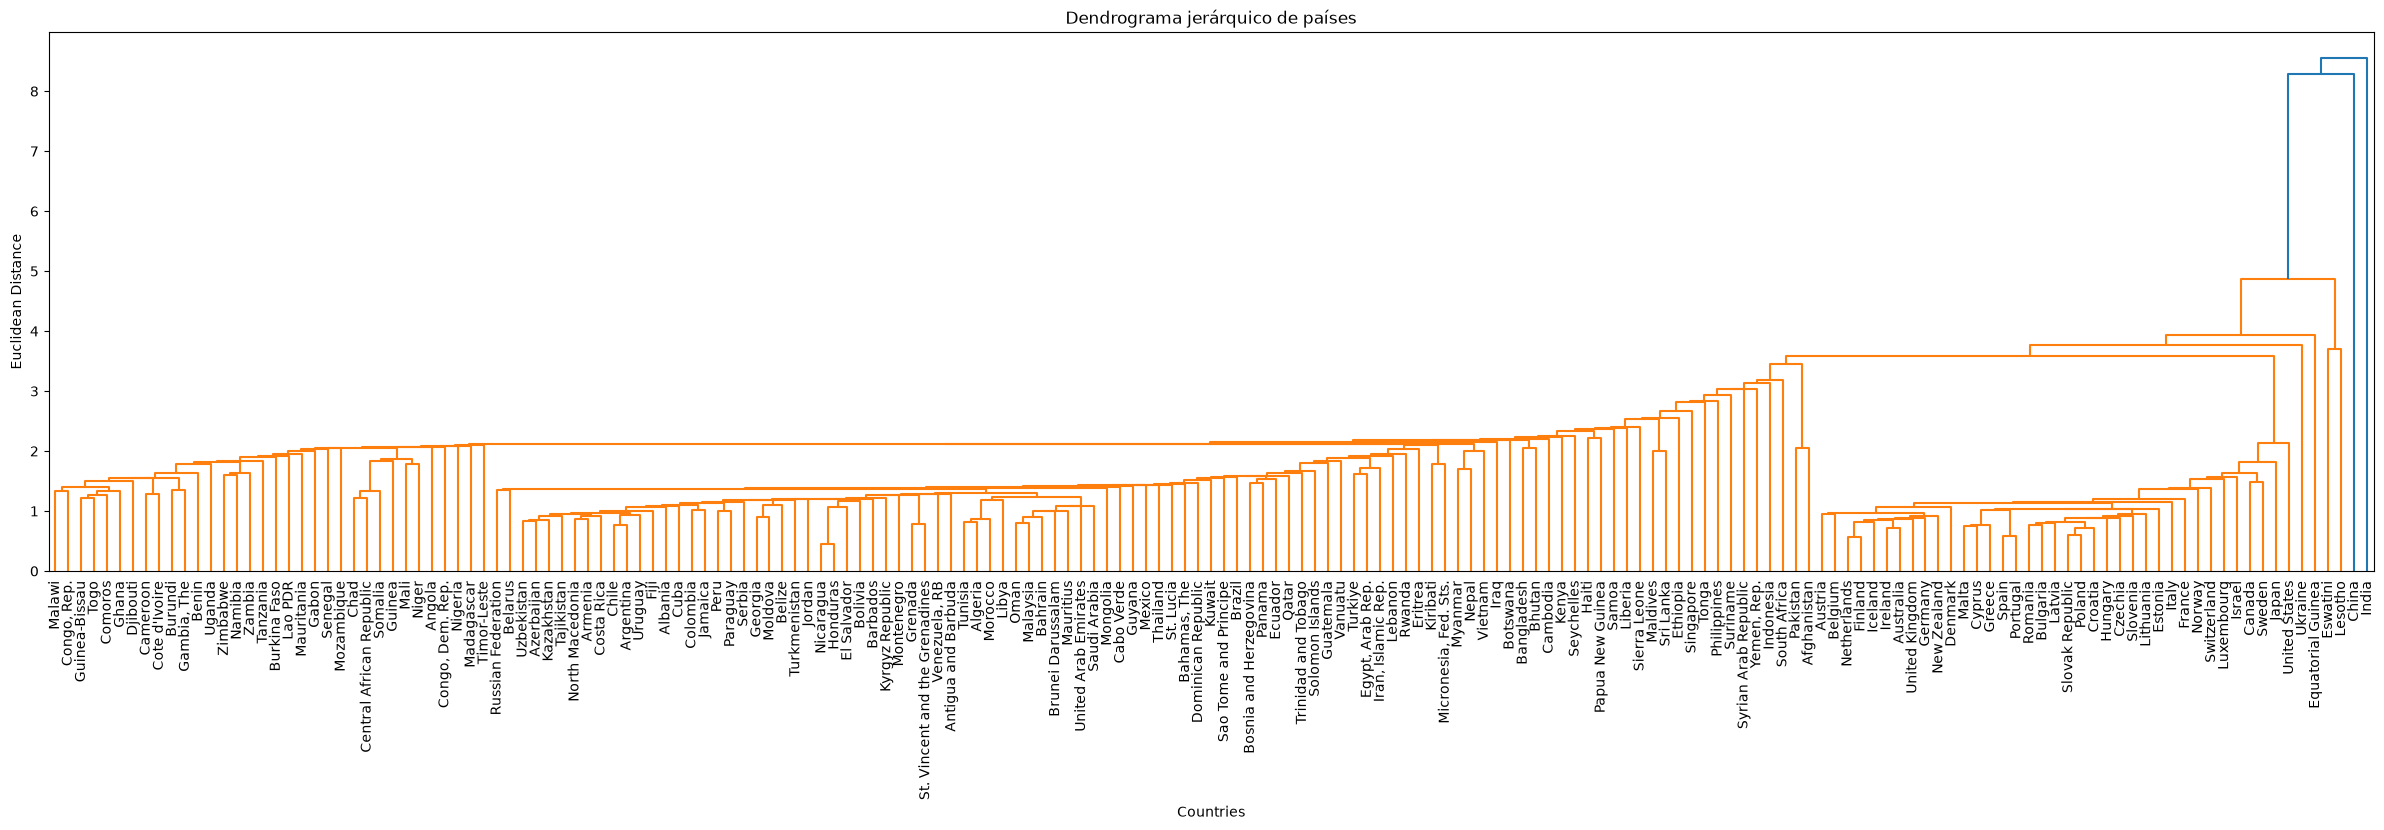

In [89]:
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

linked = linkage(features_scaled, metric="euclidean", method="single")

plt.figure(figsize=(30, 7))

dendrogram(
    linked,
    orientation='top',
    labels=countries_region['Country'].tolist(),
    distance_sort='descending',
    show_leaf_counts=True,
    leaf_font_size=10
)

plt.xlabel('Countries')
plt.ylabel('Euclidean Distance')
plt.title('Dendrograma jerárquico de países')
plt.show()

Podemos observar que existen algunos grupos claramente distinguibles entre sí (los marcados con diferentes colores). También podemos ver que India y China son dos países con bastantes diferencias respecto al resto, y que cuesta mucho unirlos con los demás. Esto nos indica que ambos son outliers, y puede deberse a varios factores: errores estadísticos, formas de medición diferentes, o simplemente países cuyas características son realmente muy diferentes al resto.

In [74]:
from sklearn.cluster import AgglomerativeClustering
import numpy as np

# Crear el modelo de clustering aglomerativo
agglomerative = AgglomerativeClustering(
    n_clusters=4,
    metric="euclidean",
    linkage="single"
)

# Obtener los clusters
clusters_agglomerative = agglomerative.fit_predict(features_scaled)

# Crear un DataFrame con los países y sus clusters
cluster_df_agglomerative = datos_paises[['Country', 'Region']].copy()
cluster_df_agglomerative['Cluster'] = clusters_agglomerative

# Imprimir los países de cada cluster
for k in np.unique(clusters_agglomerative):
    print(f'Cluster {k}')
    print(
        cluster_df_agglomerative[
            cluster_df_agglomerative['Cluster'] == k
        ][['Country', 'Region']]
    )
    print('======')

Cluster 0
                Country          Region
0     Brunei Darussalam            Asia
1          Saudi Arabia     Middle East
3             Lithuania  European Union
4               Estonia  European Union
5                  Togo          Africa
..                  ...             ...
174               Spain  European Union
175  Russian Federation  Rest of Europe
176             Bahrain     Middle East
177            Cameroon          Africa
178       Venezuela, RB   South America

[175 rows x 2 columns]
Cluster 1
      Country  Region
9     Lesotho  Africa
141  Eswatini  Africa
Cluster 2
    Country Region
167   China   Asia
Cluster 3
  Country Region
2   India   Asia


In [76]:
from scipy.cluster.hierarchy import fcluster
# Alturas a evaluar: percentiles de las distancias de unión
alturas = np.unique(
    np.quantile(linked[:, 2], np.linspace(0.10, 0.95, 30))
)

resultados_umbral = []

for umbral in alturas:
    etiquetas = fcluster(linked, t=umbral, criterion='distance')
    n_clusters = len(np.unique(etiquetas))

    # Las métricas requieren al menos 2 clusters
    if 2 <= n_clusters < len(features_scaled):
        resultados_umbral.append({
            'Umbral': umbral,
            'Cantidad_clusters': n_clusters,
            'Silhouette': silhouette_score(features_scaled, etiquetas),
            'Davies_Bouldin': davies_bouldin_score(
                features_scaled, etiquetas
            ),
            'Calinski_Harabasz': calinski_harabasz_score(
                features_scaled, etiquetas
            )
        })

tabla_umbral = pd.DataFrame(resultados_umbral)
print(tabla_umbral.round(3).to_string(index=False))

 Umbral  Cantidad_clusters  Silhouette  Davies_Bouldin  Calinski_Harabasz
  0.857                161       0.036           0.240             51.335
  0.887                156       0.033           0.260             42.453
  0.917                150       0.034           0.282             38.850
  0.953                145       0.038           0.349             33.617
  0.996                140       0.028           0.415             25.657
  1.038                135       0.016           0.416             22.641
  1.088                130       0.027           0.402             22.030
  1.135                124      -0.018           0.416             15.466
  1.186                119      -0.009           0.406             15.453
  1.210                114       0.009           0.400             15.078
  1.268                109       0.004           0.420             15.202
  1.300                104       0.005           0.430             15.887
  1.358                 99      -0.022

In [77]:
distancias = ['euclidean', 'cityblock', 'cosine']
k_elegido = 2

resultados_distancias = {}
metricas_distancias = []

for distancia in distancias:
    linked_dist = linkage(
        features_scaled,
        metric=distancia,
        method='single'
    )

    # Obtener K grupos a partir del dendrograma
    modelo = AgglomerativeClustering(
        n_clusters=k_elegido,
        metric=distancia,
        linkage='single'
    )

    etiquetas = modelo.fit_predict(features_scaled)
    resultados_distancias[distancia] = etiquetas

    metricas_distancias.append({
        'Distancia': distancia,
        'Silhouette': silhouette_score(
            features_scaled, etiquetas, metric=distancia
        ),
        'Davies-Bouldin': davies_bouldin_score(
            features_scaled, etiquetas
        ),
        'Tamaño mínimo': pd.Series(etiquetas).value_counts().min(),
        'Tamaño máximo': pd.Series(etiquetas).value_counts().max()
    })

tabla_distancias = pd.DataFrame(metricas_distancias)
print(tabla_distancias.round(3))

   Distancia  Silhouette  Davies-Bouldin  Tamaño mínimo  Tamaño máximo
0  euclidean       0.560           0.323              1            178
1  cityblock       0.451           0.323              1            178
2     cosine      -0.079           1.308              1            178


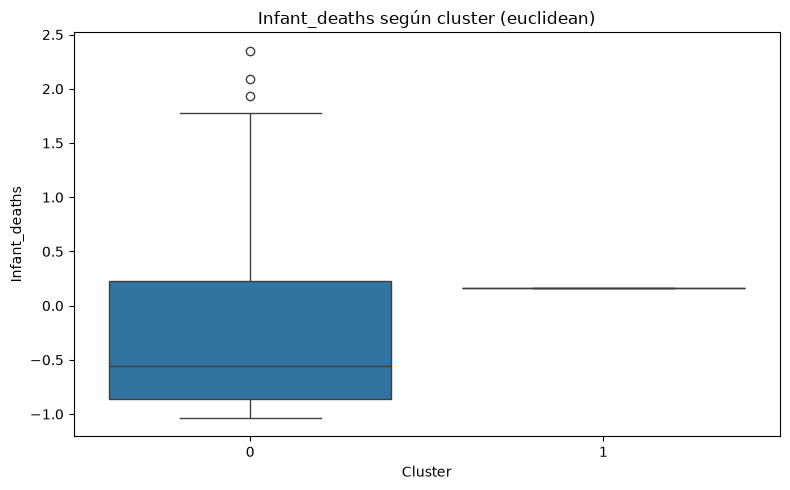

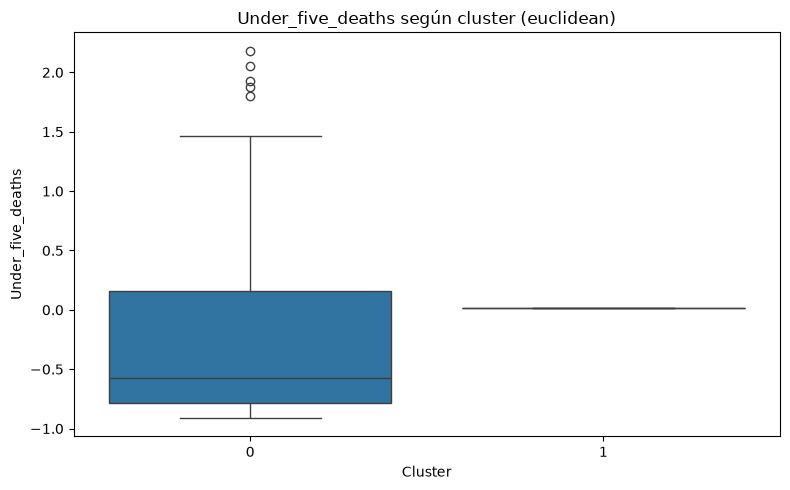

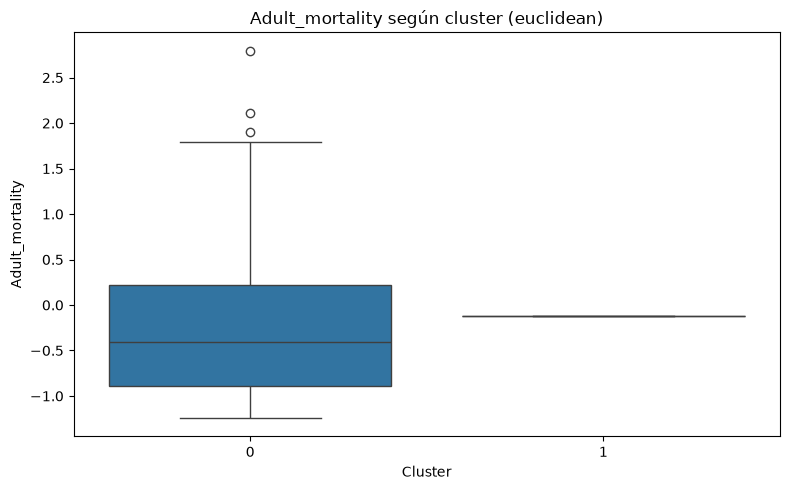

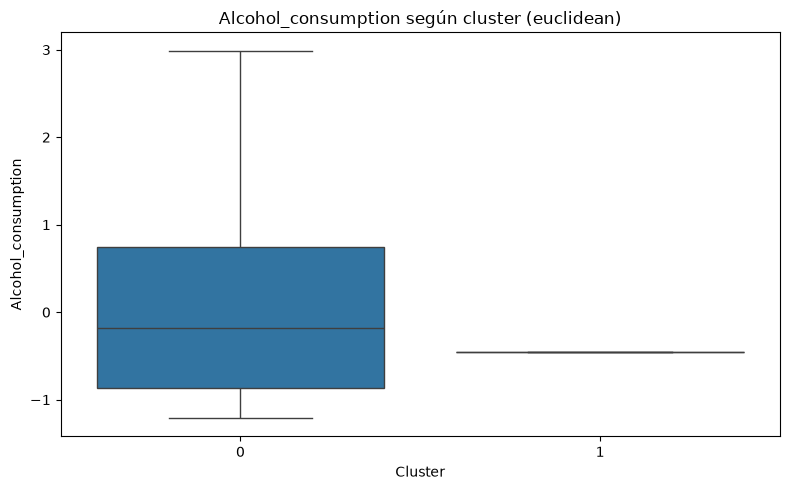

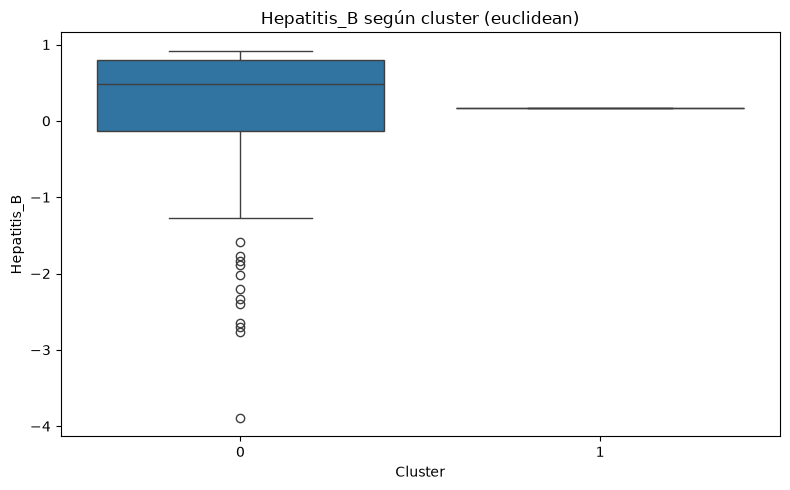

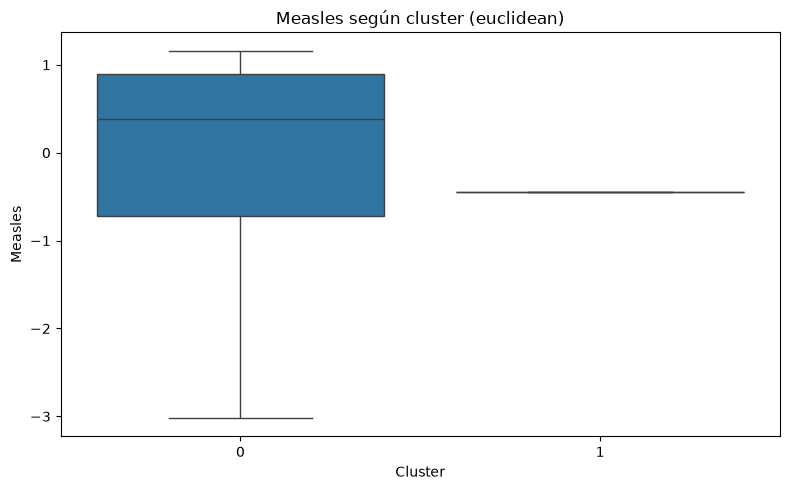

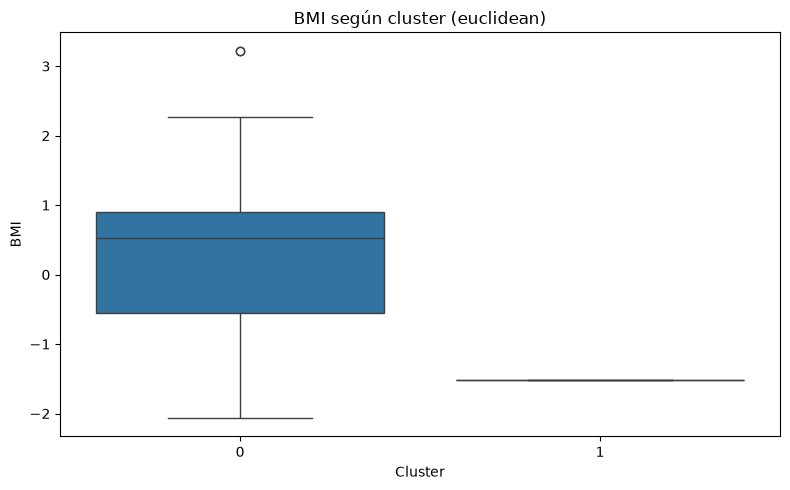

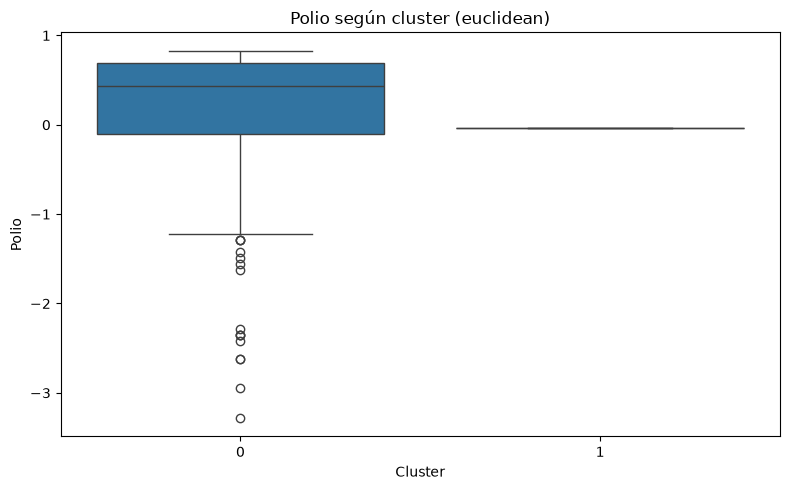

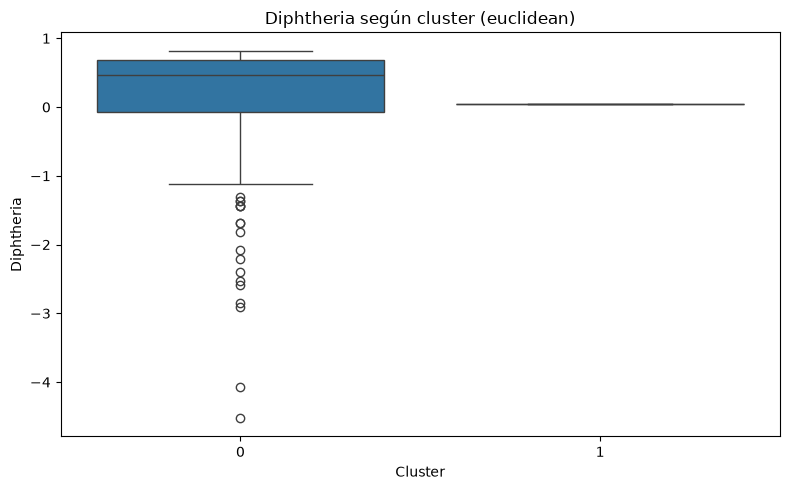

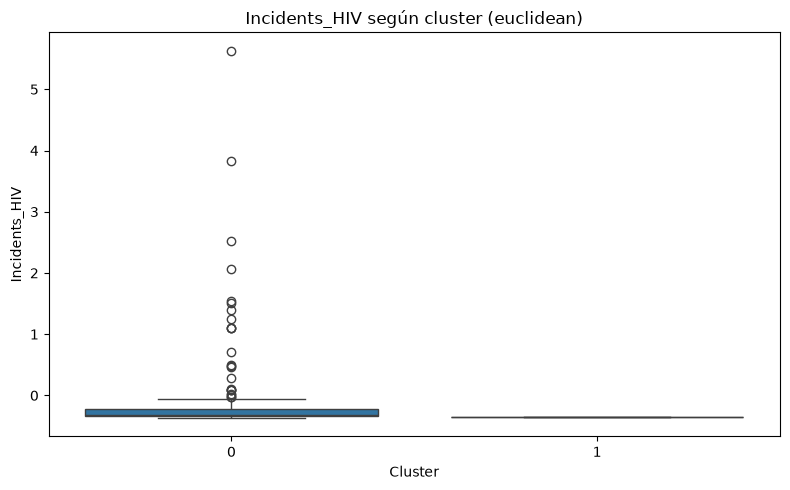

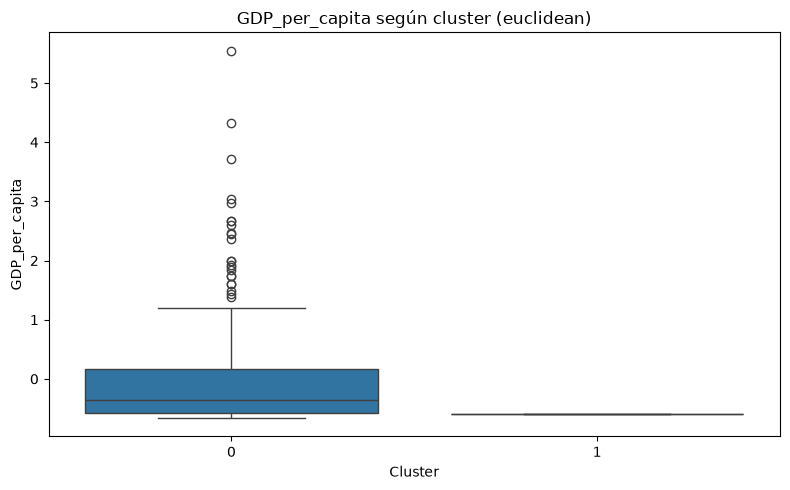

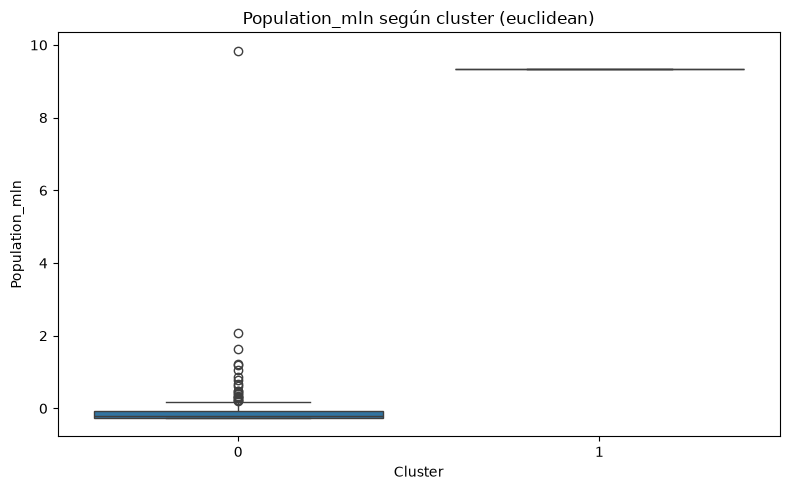

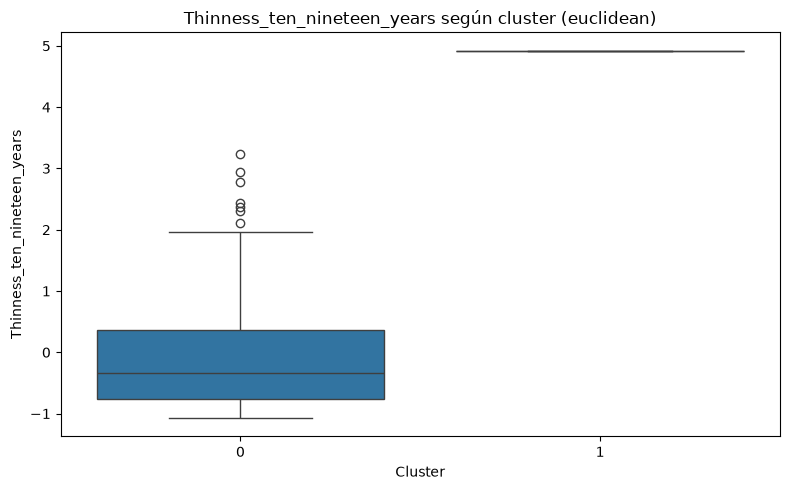

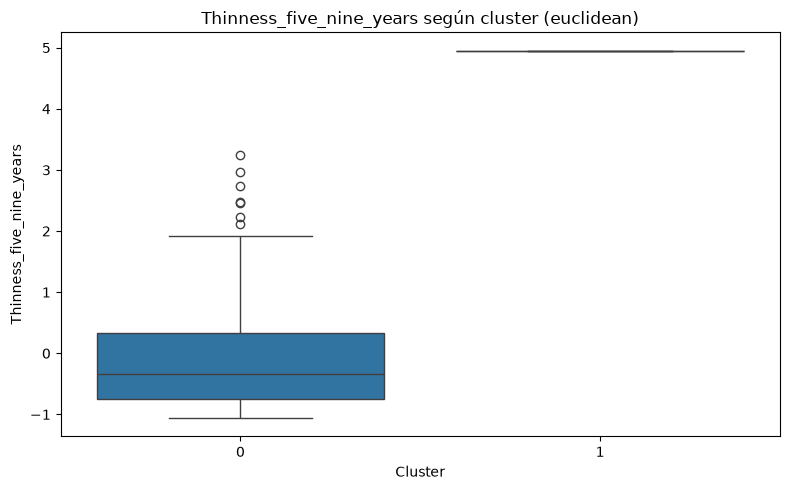

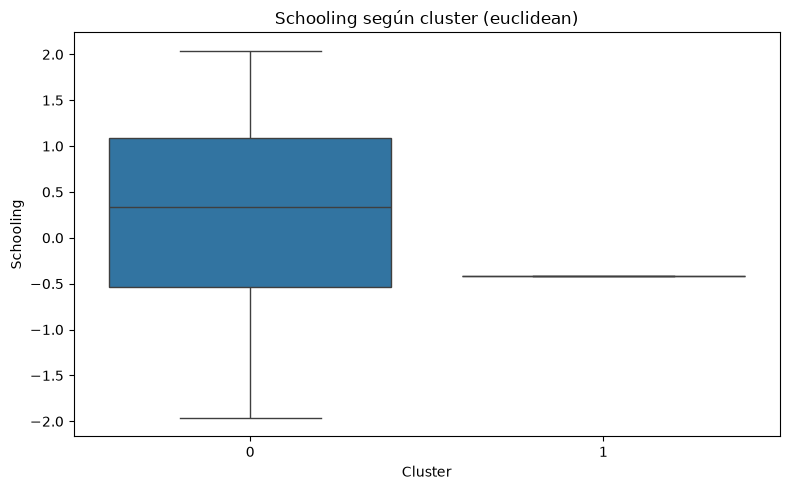

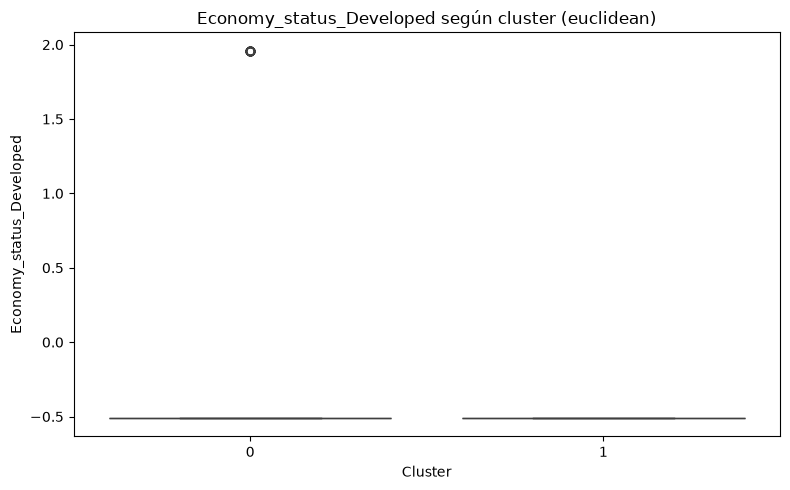

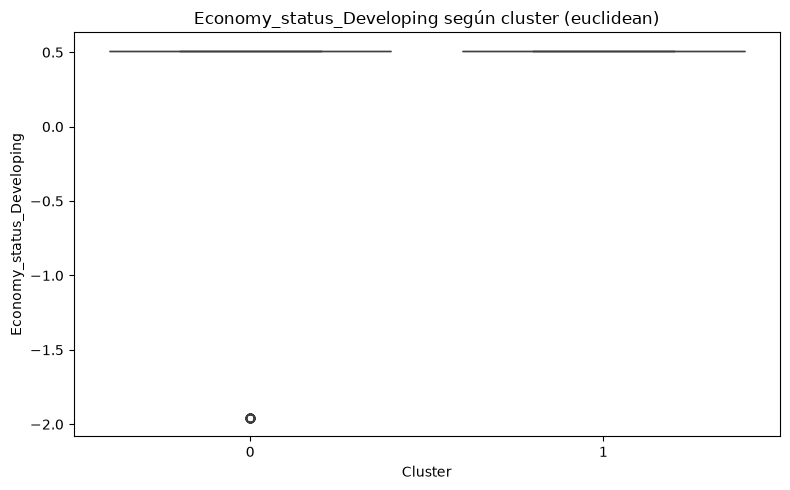

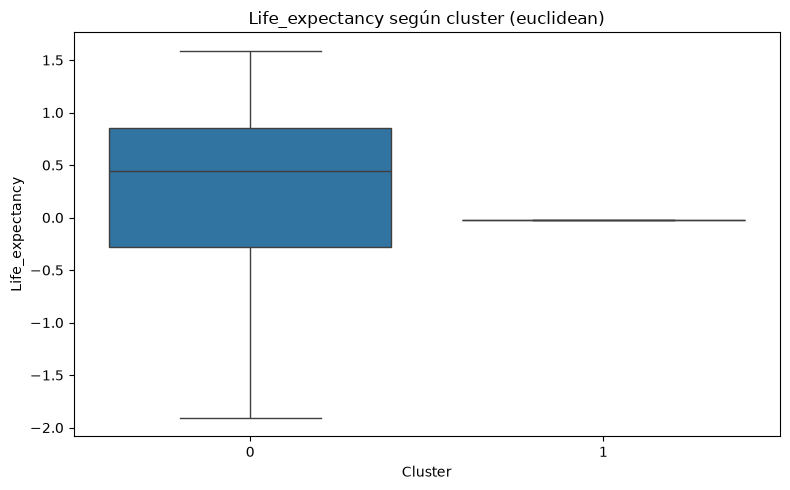

In [78]:
import seaborn as sns

distancia_elegida = 'euclidean'

datos_boxplot = datos_paises.copy()
datos_boxplot['Cluster'] = resultados_distancias[distancia_elegida]

variables = features_life.columns.tolist()

for variable in variables:
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=datos_boxplot,
        x='Cluster',
        y=variable
    )

    plt.title(f'{variable} según cluster ({distancia_elegida})')
    plt.xlabel('Cluster')
    plt.ylabel(variable)
    plt.tight_layout()
    plt.show()

K-means
DB score: 1.2843
Silhouette score: 0.3505
----------
Hierarchical Clustering
DB score: 0.3234
Silhouette score: 0.5604
----------


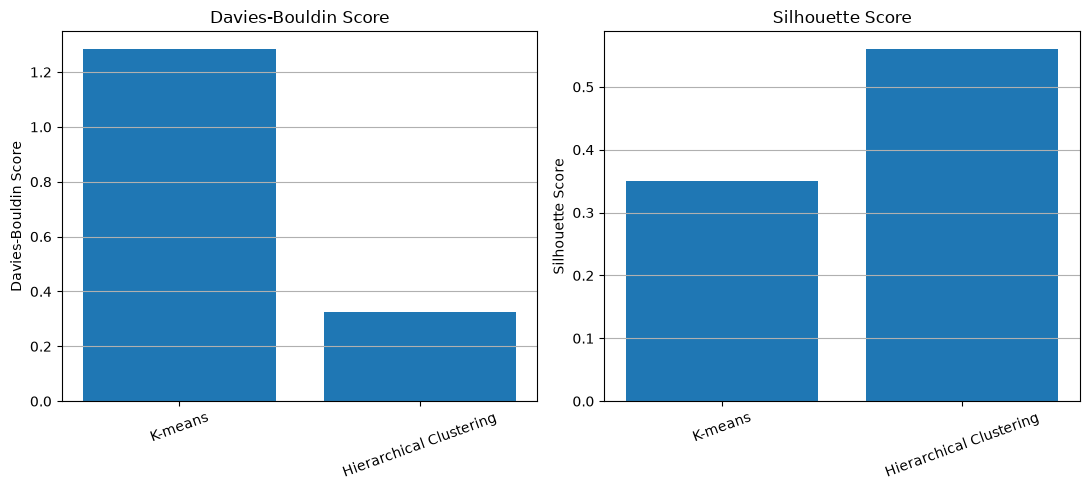

In [87]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import davies_bouldin_score, silhouette_score
import numpy as np
import matplotlib.pyplot as plt

# Generamos ambos clustering sobre los mismos 179 países
agglomerative = AgglomerativeClustering(
    n_clusters=2,
    metric='euclidean',
    linkage='single'
)

clusters_agglomerative = agglomerative.fit_predict(features_scaled)

# Algoritmos a comparar
clusters_to_compare = [
    clusters_life_kmeans,
    clusters_agglomerative
]

clustering_methods = [
    'K-means',
    'Hierarchical Clustering'
]

db_scores = np.zeros(len(clusters_to_compare))
silhouette_scores = np.zeros(len(clusters_to_compare))

for i, clusters in enumerate(clusters_to_compare):
    db_scores[i] = davies_bouldin_score(features_scaled, clusters)
    silhouette_scores[i] = silhouette_score(features_scaled, clusters)

    print(clustering_methods[i])
    print(f'DB score: {db_scores[i]:.4f}')
    print(f'Silhouette score: {silhouette_scores[i]:.4f}')
    print('----------')

# Graficar las métricas
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
plt.subplots_adjust(wspace=0.5)

axes[0].bar(clustering_methods, db_scores)
axes[0].set_title('Davies-Bouldin Score')
axes[0].set_ylabel('Davies-Bouldin Score')
axes[0].tick_params(axis='x', rotation=20)
axes[0].grid(axis='y')

axes[1].bar(clustering_methods, silhouette_scores)
axes[1].set_title('Silhouette Score')
axes[1].set_ylabel('Silhouette Score')
axes[1].tick_params(axis='x', rotation=20)
axes[1].grid(axis='y')

plt.tight_layout()
plt.show()

El clustering jerárquico tiene un Davies-Bouldin considerablemente menor, lo que indica una mejor relación entre la dispersión de sus grupos y su separación.

El valor del jerárquico es mayor: en promedio, sus países presentan una mejor separación entre el grupo al que pertenecen y el grupo vecino.
Un Silhouette de 0.5604 suele ser una señal favorable de estructura de clusters, aunque no garantiza por sí solo que los grupos sean útiles o tengan sentido desde el punto de vista del problema.

# Ejercicio 3

In [92]:
if not path.exists("ObesityDataSet_raw_and_data_sinthetic.csv"):
    download("https://ignaciorlando.github.io/datasets/data-science/ObesityDataSet_raw_and_data_sinthetic.csv")
else: 
    print("Ya existe el archivo")

leer_datos_Obesity = pd.read_csv("ObesityDataSet_raw_and_data_sinthetic.csv")
leer_datos_Obesity.info()

<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age                             2111 non-null   float64
 1   Gender                          2111 non-null   str    
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   CALC                            2111 non-null   str    
 5   FAVC                            2111 non-null   str    
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   SCC                             2111 non-null   str    
 9   SMOKE                           2111 non-null   str    
 10  CH2O                            2111 non-null   float64
 11  family_history_with_overweight  2111 non-null   str    
 12  FAF                             2111 non-null

In [94]:
leer_datos_Obesity.head(   )

,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,NObeyesdad
0,21.0,Female,1.62,64.0,no,no,2.0,3.0,no,no,2.0,yes,0.0,1.0,Sometimes,Public_Transportation,Normal_Weight
1,21.0,Female,1.52,56.0,Sometimes,no,3.0,3.0,yes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,23.0,Male,1.80,77.0,Frequently,no,2.0,3.0,no,no,2.0,yes,2.0,1.0,Sometimes,Public_Transportation,Normal_Weight
3,27.0,Male,1.80,87.0,Frequently,no,3.0,3.0,no,no,2.0,no,2.0,0.0,Sometimes,Walking,Overweight_Level_I
4,22.0,Male,1.78,89.8,Sometimes,no,2.0,1.0,no,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [95]:
variables = ['FAVC', 'FCVC', 'NCP', 'CAEC', 'CH2O', 'CALC']

# Seleccionar las variables de interés
datos_habitos = leer_datos_Obesity[variables].copy()

# Tratar los valores faltantes, si existen
datos_habitos = datos_habitos.dropna()

# Convertir las variables en indicadores binarios
datos_encoded = pd.get_dummies(
    datos_habitos.astype(str),
    columns=variables,
    dtype=int
)

La distancia de Jaccard mide la diferencia entre conjuntos de características presentes. En una representación binaria, compara los indicadores que están activados en dos individuos. Es útil cuando interesa comparar la presencia de categorías, aunque hay que tener presente que los ceros compartidos no contribuyen a la similitud.

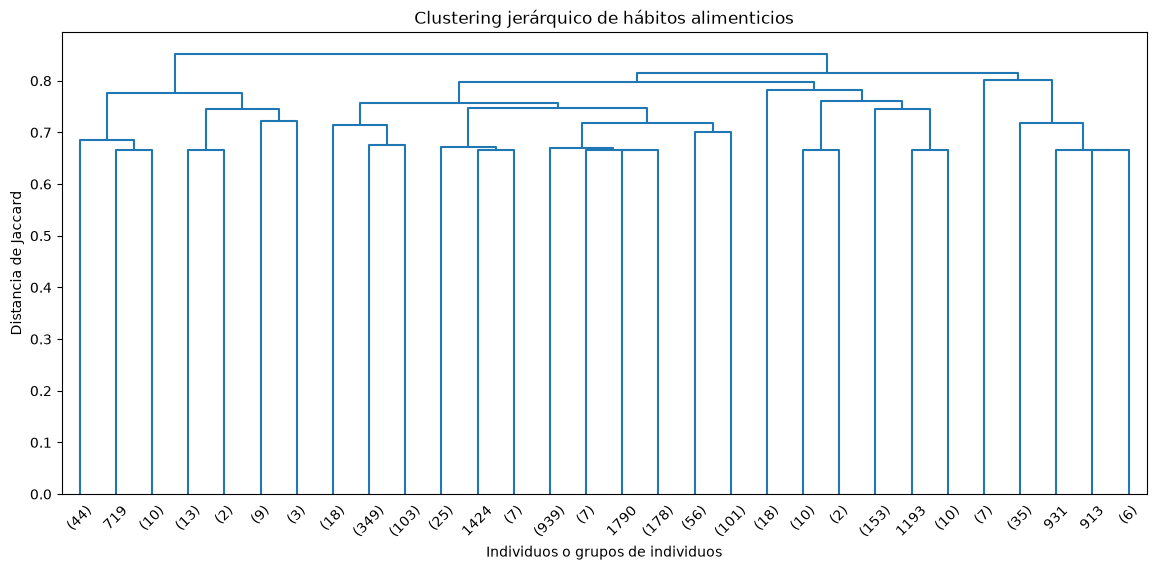

In [96]:
from scipy.spatial.distance import pdist

# Calcular las distancias de Jaccard
distancias_jaccard = pdist(datos_encoded, metric='jaccard')

# Construir el clustering jerárquico
linked_jaccard = linkage(
    distancias_jaccard,
    method='average'
)

# Mostrar el dendrograma
plt.figure(figsize=(14, 6))

dendrogram(
    linked_jaccard,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True
)

plt.xlabel('Individuos o grupos de individuos')
plt.ylabel('Distancia de Jaccard')
plt.title('Clustering jerárquico de hábitos alimenticios')
plt.show()

In [97]:
clusters_obesidad = fcluster(
    linked_jaccard,
    t=4,
    criterion='maxclust'
)

resultado_habitos = datos_habitos.copy()
resultado_habitos['Cluster'] = clusters_obesidad

print(resultado_habitos['Cluster'].value_counts().sort_index())

Cluster
1      82
2    1979
3       7
4      43
Name: count, dtype: int64


In [98]:
for variable in variables:
    print(f'\nDistribución de {variable} por cluster:')

    tabla = pd.crosstab(
        resultado_habitos['Cluster'],
        resultado_habitos[variable],
        normalize='index'
    ) * 100

    print(tabla.round(1))


Distribución de FAVC por cluster:
FAVC       no    yes
Cluster             
1        36.6   63.4
2        10.8   89.2
3         0.0  100.0
4         2.3   97.7

Distribución de FCVC por cluster:
FCVC     1.000000  1.003566  1.005578  1.008760  1.031149  1.036159  1.036414  \
Cluster                                                                         
1             0.0       0.0       0.0       0.0       0.0       0.0       0.0   
2             1.6       0.0       0.1       0.1       0.1       0.1       0.1   
3             0.0      14.3       0.0       0.0       0.0       0.0       0.0   
4             2.3       0.0       0.0       0.0       0.0       0.0       0.0   

FCVC     1.052699  1.053534  1.063449  ...  2.992205  2.992329  2.994480  \
Cluster                                ...                                 
1             0.0       0.0       0.0  ...       0.0       0.0       0.0   
2             0.1       0.1       0.1  ...       0.1       0.1       0.1   
3            

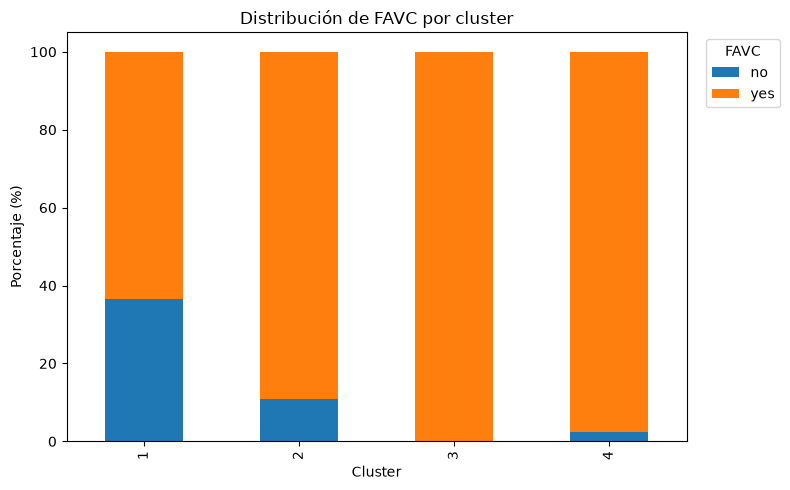

/tmp/ipykernel_12702/3163954937.py:18: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()




/tmp/ipykernel_12702/3163954937.py:18: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()




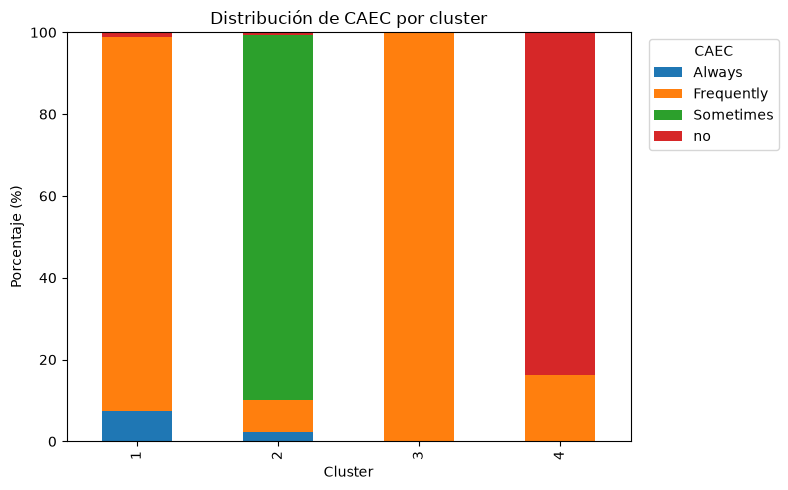

/tmp/ipykernel_12702/3163954937.py:18: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()




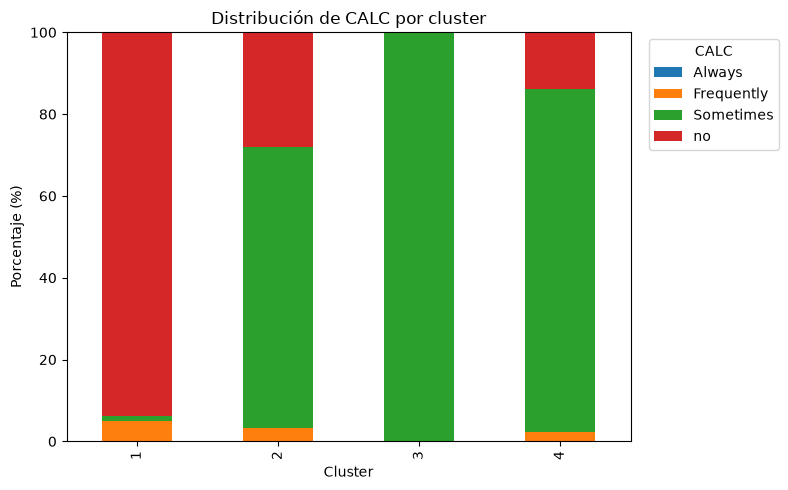

In [99]:
for variable in variables:
    tabla = pd.crosstab(
        resultado_habitos['Cluster'],
        resultado_habitos[variable],
        normalize='index'
    ) * 100

    tabla.plot(
        kind='bar',
        stacked=True,
        figsize=(8, 5)
    )

    plt.title(f'Distribución de {variable} por cluster')
    plt.xlabel('Cluster')
    plt.ylabel('Porcentaje (%)')
    plt.legend(title=variable, bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()

In [100]:
variables_categoricas = ['FAVC', 'CAEC', 'CALC']

resultados_categoricos = []

for variable in variables_categoricas:
    # Tabla de contingencia
    tabla = pd.crosstab(
        resultado_habitos['Cluster'],
        resultado_habitos[variable]
    )

    chi2, p_valor, grados_libertad, esperados = chi2_contingency(tabla)

    resultados_categoricos.append({
        'Variable': variable,
        'Chi-cuadrado': chi2,
        'Grados de libertad': grados_libertad,
        'p-valor': p_valor,
        'Mínimo esperado': esperados.min()
    })

    print(f'\nVariable: {variable}')
    print(tabla)
    print(f'Chi-cuadrado: {chi2:.3f}')
    print(f'p-valor: {p_valor:.5f}')
    print(f'Mínima frecuencia esperada: {esperados.min():.2f}')

tabla_categoricas = pd.DataFrame(resultados_categoricos)


Variable: FAVC
FAVC      no   yes
Cluster           
1         30    52
2        214  1765
3          0     7
4          1    42
Chi-cuadrado: 55.615
p-valor: 0.00000
Mínima frecuencia esperada: 0.81

Variable: CAEC
CAEC     Always  Frequently  Sometimes  no
Cluster                                   
1             6          75          0   1
2            47         153       1765  14
3             0           7          0   0
4             0           7          0  36
Chi-cuadrado: 1858.388
p-valor: 0.00000
Mínima frecuencia esperada: 0.17

Variable: CALC
CALC     Always  Frequently  Sometimes   no
Cluster                                    
1             0           4          1   77
2             1          65       1357  556
3             0           0          7    0
4             0           1         36    6
Chi-cuadrado: 176.748
p-valor: 0.00000
Mínima frecuencia esperada: 0.00


In [101]:
from scipy.stats import kruskal

variables_ordinales = ['FCVC', 'NCP', 'CH2O']

resultados_ordinales = []

for variable in variables_ordinales:
    grupos = [
        grupo[variable].dropna().to_numpy()
        for _, grupo in resultado_habitos.groupby('Cluster')
    ]

    # Excluir grupos vacíos, si los hubiera
    grupos = [grupo for grupo in grupos if len(grupo) > 0]

    estadistico, p_valor = kruskal(*grupos)

    resultados_ordinales.append({
        'Variable': variable,
        'Estadístico H': estadistico,
        'p-valor': p_valor
    })

    print(f'\nVariable: {variable}')
    print(f'Estadístico H: {estadistico:.3f}')
    print(f'p-valor: {p_valor:.5f}')

tabla_ordinales = pd.DataFrame(resultados_ordinales)


Variable: FCVC
Estadístico H: 95.844
p-valor: 0.00000

Variable: NCP
Estadístico H: 58.419
p-valor: 0.00000

Variable: CH2O
Estadístico H: 81.720
p-valor: 0.00000


In [102]:
print(
    pd.crosstab(
        resultado_habitos['Cluster'],
        resultado_habitos['FAVC'],
        normalize='index'
    ).mul(100).round(1)
)

FAVC       no    yes
Cluster             
1        36.6   63.4
2        10.8   89.2
3         0.0  100.0
4         2.3   97.7
